In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

In [2]:
f = open('h01/info.json') 
info = json.load(f) 

In [3]:
ind_cell_df = pd.read_csv('h01/neurons_positions_h01_full.csv')
ind_cell_df.rename({'Unnamed: 0': 'id_new'}, axis=1, inplace=True)
ind_cell_df

,id_new,agglo_seg,x,y,z,type,layer,linfo,info,neuron,...,inhibitory synapses,cortical layer,cell type,synapses,repetitions,labels,glia,spiny,pyr,EI
0,50292,105572531279,1336832,2275647,169884,pyramidal neuron,7,7,layer-unclassifiedpyramidalneuron,True,...,0,0,0,0,1,pyramidal neuron_layer-unclassifiedpyramidalne...,False,False,True,exc
1,2924,6525902368,1523184,2008880,91605,pyramidal neuron,7,7,WMpyramidalneuron,True,...,835,White matter,pyramidal neuron,3754,1,pyramidal neuron_WMpyramidalneuron_pyramidal n...,False,False,True,exc
2,11087,6526033781,1565984,1840864,121173,pyramidal neuron,6,6,L6pyramidalneuronbipolar,True,...,883,Layer 6,pyramidal neuron,3738,1,pyramidal neuron_L6pyramidalneuronbipolar_pyra...,False,False,True,exc
3,7714,6527305613,2122232,1725400,108501,pyramidal neuron,5,5,L5pyramidalneuron,True,...,359,Layer 5,pyramidal neuron,974,1,pyramidal neuron_L5pyramidalneuron_pyramidal n...,False,False,True,exc
4,12791,6527669458,1989968,1976000,100053,pyramidal neuron,5,6,L6pyramidalneuronbipolar,True,...,840,Layer 5,pyramidal neuron,3443,1,pyramidal neuron_L6pyramidalneuronbipolar_pyra...,False,False,True,exc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15964,5705,5344594921,961928,1605040,53760,unknown cell,7,7,WMunknown-type,False,...,290,White matter,unknown cell,861,1,unknown cell_WMunknown-type_unknown cell,False,False,False,inh
15965,2539,22611620829,1501320,1407584,57813,unknown cell,5,5,L5unknown-type,False,...,149,Layer 5,unknown cell,410,1,unknown cell_L5unknown-type_unknown cell,False,False,False,inh
15966,36102,1697644856,2505288,746104,19200,unknown cell,2,2,L2unknown-typegrey,False,...,122,Layer 3,unknown cell,294,1,unknown cell_L2unknown-typegrey_unknown cell,False,False,False,inh
15967,46453,34011994965,2039864,2090776,167637,unknown cell,5,6,L6unknown-typegrey,False,...,156,Layer 5,unknown cell,505,1,unknown cell_L6unknown-typegrey_unknown cell,False,False,False,inh


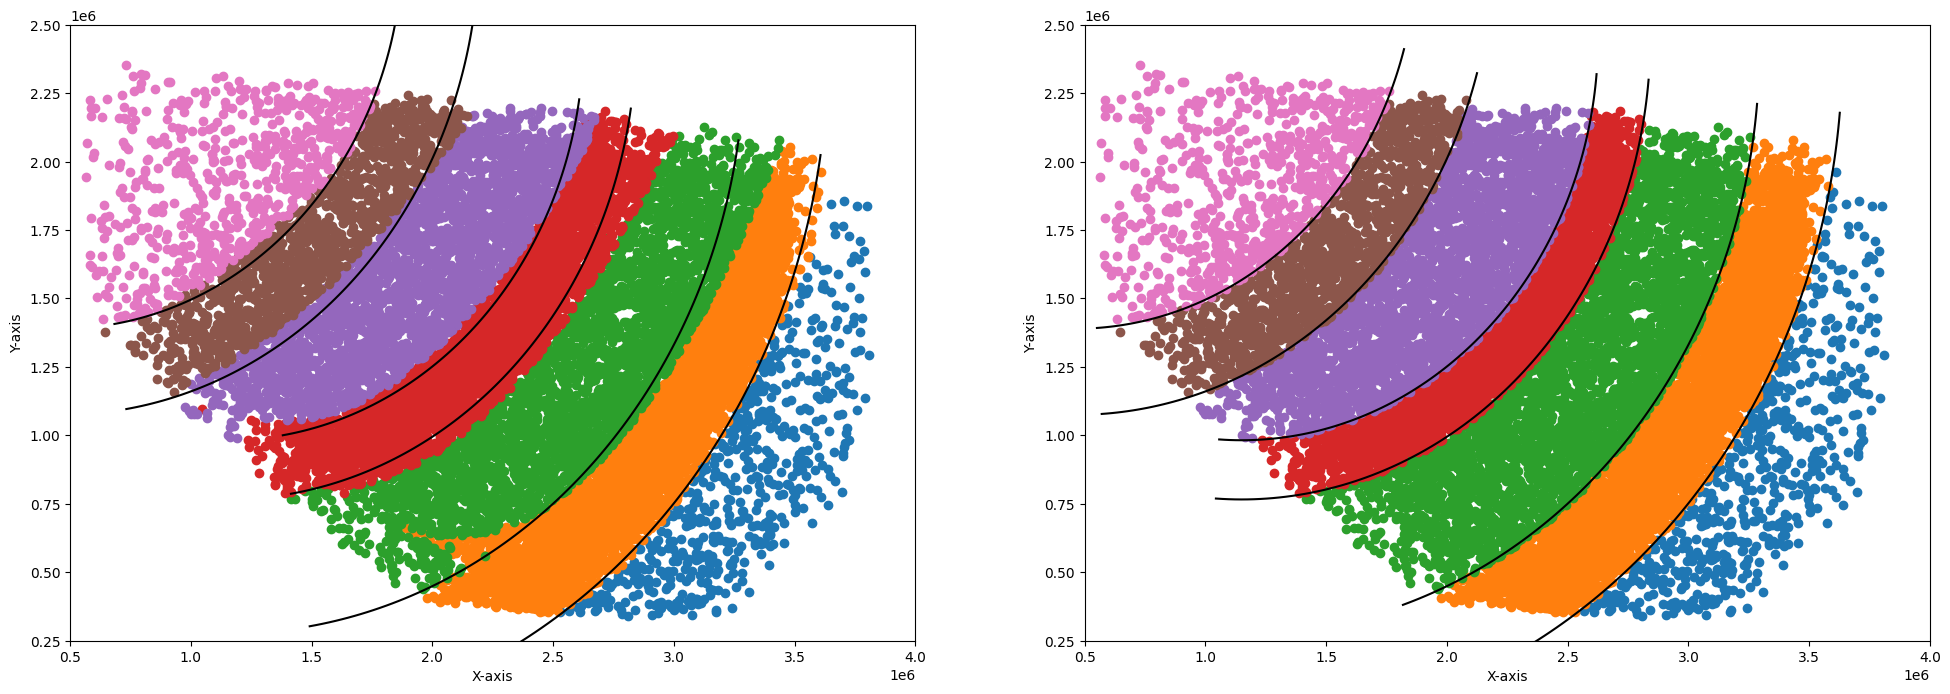

In [4]:
with open("h01/cortical_bounds_circles.json", "r") as f:
  bounds = json.load(f)

Fig = plt.figure(figsize=(24,8))

plt.subplot(1,2,1) # info label
plt.plot(ind_cell_df[ind_cell_df['linfo']==1]['x'].values,ind_cell_df[ind_cell_df['linfo']==1]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['linfo']==2]['x'].values,ind_cell_df[ind_cell_df['linfo']==2]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['linfo']==3]['x'].values,ind_cell_df[ind_cell_df['linfo']==3]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['linfo']==4]['x'].values,ind_cell_df[ind_cell_df['linfo']==4]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['linfo']==5]['x'].values,ind_cell_df[ind_cell_df['linfo']==5]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['linfo']==6]['x'].values,ind_cell_df[ind_cell_df['linfo']==6]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['linfo']==7]['x'].values,ind_cell_df[ind_cell_df['linfo']==7]['y'].values, 'o')

for cdd in bounds:    
    center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']
    
    theta = np.linspace(1.55*np.pi, 1.95*np.pi, 100)  # Adjust point density as needed
    x = 1000*(center_x + radius * np.cos(theta))
    y = 1000*(center_y + radius * np.sin(theta))

    plt.plot(x, y, color = 'k')

plt.xlim(500000,4000000)
plt.ylim(250000,2500000)
plt.xlabel('X-axis')
plt.ylabel('Y-axis');


plt.subplot(1,2,2) # multiple circles aprox
plt.plot(ind_cell_df[ind_cell_df['layer']==1]['x'].values,ind_cell_df[ind_cell_df['layer']==1]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['layer']==2]['x'].values,ind_cell_df[ind_cell_df['layer']==2]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['layer']==3]['x'].values,ind_cell_df[ind_cell_df['layer']==3]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['layer']==4]['x'].values,ind_cell_df[ind_cell_df['layer']==4]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['layer']==5]['x'].values,ind_cell_df[ind_cell_df['layer']==5]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['layer']==6]['x'].values,ind_cell_df[ind_cell_df['layer']==6]['y'].values, 'o')
plt.plot(ind_cell_df[ind_cell_df['layer']==7]['x'].values,ind_cell_df[ind_cell_df['layer']==7]['y'].values, 'o')

for cdd in bounds[0:2]:    
    center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']
    
    theta = np.linspace(1.52*np.pi, 1.91*np.pi, 100)  # Adjust point density as needed
    x = 1000*(center_x + radius * np.cos(theta))
    y = 1000*(center_y + radius * np.sin(theta))

    plt.plot(x, y, color = 'k')

for cdd in bounds[2:4]:    
    center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']
    
    theta = np.linspace(1.48*np.pi, 1.97*np.pi, 100)  # Adjust point density as needed
    x = 1000*(center_x + radius * np.cos(theta))
    y = 1000*(center_y + radius * np.sin(theta))

    plt.plot(x, y, color = 'k')

for cdd in bounds[4:6]:    
    center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']
    
    theta = np.linspace(1.6*np.pi, 1.97*np.pi, 100)  # Adjust point density as needed
    x = 1000*(center_x + radius * np.cos(theta))
    y = 1000*(center_y + radius * np.sin(theta))

    plt.plot(x, y, color = 'k')

plt.xlim(500000,4000000)
plt.ylim(250000,2500000)
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

plt.show() 


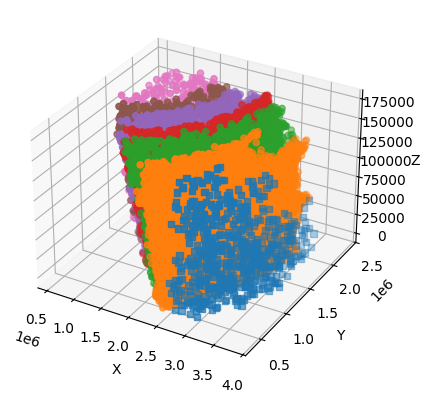

In [5]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# For each set of style and range settings, plot n random points in the box
# defined by x in [23, 32], y in [0, 100], z in [zlow, zhigh].
for m, layer in [('s', 1),  ('o', 2),  ('o', 3),('o', 4),  ('o', 5),  ('o', 6), ('o', 7)]:
    
    nodeprex = []
    nodeprez = []       
    nodeprey = [] 
    nodepremtype = []    
    for gid in range(len(ind_cell_df['x'])): 
        if ind_cell_df['layer'][gid] == layer:
            nodeprex.append(ind_cell_df['x'][gid])
            nodeprey.append(ind_cell_df['y'][gid])
            nodeprez.append(ind_cell_df['z'][gid])
            nodepremtype.append(ind_cell_df['layer'][gid])
    
    ax.scatter(nodeprex, nodeprey, nodeprez, marker=m)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.show()

In [6]:
print(np.mean(nodeprex),np.mean(nodeprey),np.mean(nodeprez))

1176594.060518732 1910370.5216138328 85247.20172910663


In [7]:
nodeprex = []
nodeprez = []       
nodeprey = [] 
nodepremtype = []    
for gid in range(len(ind_cell_df['x'])): 
    if ind_cell_df['linfo'][gid] == 4:    
        nodeprex.append(ind_cell_df['x'][gid])
        nodeprey.append(ind_cell_df['y'][gid])
        nodeprez.append(ind_cell_df['z'][gid])
        nodepremtype.append(ind_cell_df['linfo'][gid])
        
print("%.2f, %.2f, %.2f " % (np.mean(nodeprex)/1,np.mean(nodeprey)/1,np.mean(nodeprez)/1))

2206285.40, 1382487.94, 88682.37 


In [8]:
x0, y0, z0 = 2206285.40, 1382487.94, 88682.37
x0, y0, z0

(2206285.4, 1382487.94, 88682.37)

In [9]:
nodeprex = []
nodeprez = []       
nodeprey = [] 
nodepremtype = []    
for gid in range(len(ind_cell_df['x'])): 
    if ind_cell_df['linfo'][gid] == 6:    
        nodeprex.append(ind_cell_df['x'][gid])
        nodeprey.append(ind_cell_df['y'][gid])
        nodeprez.append(ind_cell_df['z'][gid])
        nodepremtype.append(ind_cell_df['linfo'][gid])
        
# print("%.2f %.2f %.2f " % (np.mean(nodeprex)/1000,np.mean(nodeprey)/1000,np.mean(nodeprez)/1000))
print("%.2f, %.2f, %.2f " % (np.mean(nodeprex)/1,np.mean(nodeprey)/1,np.mean(nodeprez)/1))

1488675.42, 1705368.38, 87497.73 


In [10]:
x6, y6, z6 = 1488675.42, 1705368.38, 87497.73
x6, y6, z6

(1488675.42, 1705368.38, 87497.73)

In [11]:
vx, vy, vz = x0 - x6, y0 - y6, z0 - z6
vx, vy, vz

(717609.98, -322880.43999999994, 1184.6399999999994)

In [12]:
t = -3.074490965134013
xt, yt, zt = x0 + vx*t, y0+ vy*t, z0+ vz*t
xt, yt, zt

(0.0, 2375180.9355984945, 85040.20502306364)

In [13]:
t = 2.5
xt2, yt2, zt2 = x0 + vx*t, y0+ vy*t, z0+ vz*t
xt2, yt2, zt2 

(4000310.3499999996, 575286.8400000001, 91643.97)

In [14]:
# xxx = 1000.0*np.array([462.2683543371059,462.2683543371059,1149.931366648436,1149.931366648436,1158.159407138949,1158.159407138949])
# yyy = 1000.0*np.array([2805.973374970087,2805.973374970087,2458.417758523231,2458.417758523231,2411.737892996198,2411.737892996198])

/tmp/ipykernel_2650142/2534614298.py:45: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype, cmap=plt.cm.get_cmap('gnuplot', 12))


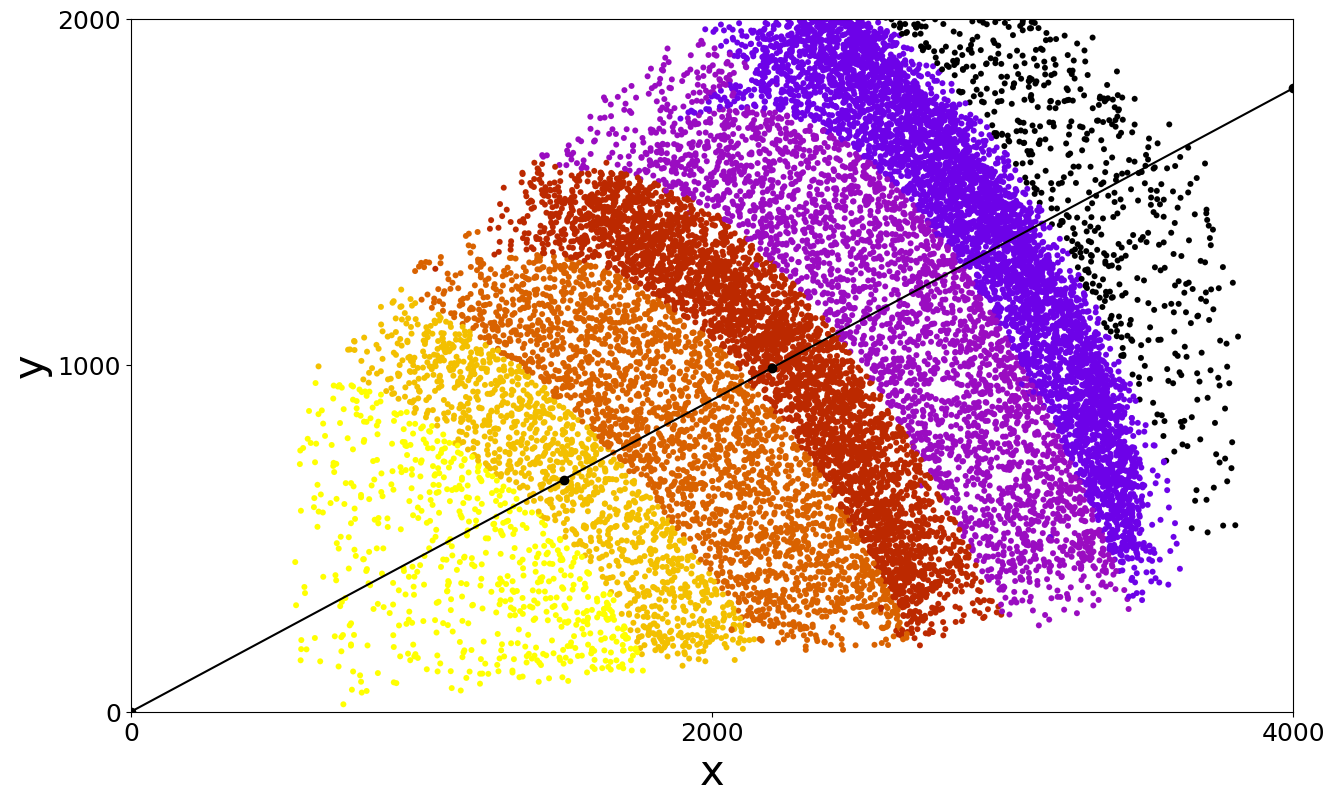

In [15]:
nodeprex = []
nodeprez = []       
nodeprey = [] 
nodepremtype = []    
for gid in range(len(ind_cell_df['x'])): 
    nodeprex.append(ind_cell_df['x'][gid])
    nodeprey.append(ind_cell_df['y'][gid])
    nodeprez.append(ind_cell_df['z'][gid])
    nodepremtype.append(ind_cell_df['layer'][gid])


# plot the results
# fig=plt.figure(figsize=(15,6))

# for ii,reg in enumerate(['xS1FL']):
    

#     plt.subplot(1,2,1)
#     plt.scatter(nodeprex,-1.0*np.array(nodeprey)+2321399.37744675, lw=0.05, s=18,
#                 c=nodepremtype, cmap=plt.cm.get_cmap('gnuplot', 12))
#     plt.xlabel('x', fontsize=12)
#     plt.ylabel('y', fontsize=12)
#     plt.plot([xt,x6,x0,xt2],-1.0*np.array([yt-2321399.37744675,y6-2321399.37744675,y0-2321399.37744675,yt2-2321399.37744675]),'-ok')
#     # plt.plot(xxx,yyy,'ob')
#     plt.ylim(0, 4000000)
#     plt.xlim(0, 4000000)

nodeprex = []
nodeprez = []       
nodeprey = [] 
nodepremtype = []    
for gid in range(len(ind_cell_df['x'])): 
    nodeprex.append(ind_cell_df['x'][gid])
    nodeprey.append(ind_cell_df['y'][gid])
    nodeprez.append(ind_cell_df['z'][gid])
    nodepremtype.append(ind_cell_df['linfo'][gid])


fig=plt.figure(figsize=(15,9))
for ii,reg in enumerate(['xS1FL']):
    

    # plt.subplot(1,2,2)
    plt.scatter(nodeprex,-1.0*np.array(nodeprey)+2375180.9355984945, lw=0.05, s=18,
                c=nodepremtype, cmap=plt.cm.get_cmap('gnuplot', 12))
    plt.plot([xt,x6,x0,xt2],-1.0*np.array([yt-2375180.9355984945,y6-2375180.9355984945,y0-2375180.9355984945,yt2-2375180.9355984945]),'-ok')
    plt.xlabel('x', fontsize=30)
    plt.ylabel('y', fontsize=30)
    plt.ylim(0, 2000000)
    plt.xlim(0, 4000000);
    plt.yticks([0, 1000000, 2000000],[0, 1000, 2000],fontsize=18)
    plt.xticks([0, 2000000, 4000000],[0, 2000, 4000],fontsize=18);


    # plt.subplot(1,3,2)
    # # plt.scatter(nodeprex,nodeprez, lw=0.05, s=18,
    # #             c=nodepremtype, cmap=plt.cm.get_cmap('gnuplot', 12))
    # plt.xlabel('x', fontsize=12)
    # plt.ylabel('z', fontsize=12)
    # plt.plot([3942.8243701921465-xt,3560.8979394929374-xt,xt-xt],[-2463.3882640928678-zt,-2960.494375047068-zt,zt-zt],'-ok')


    # plt.subplot(1,3,3)
    # # plt.scatter(nodeprey,nodeprez, lw=0.05, s=18,
    # #             c=nodepremtype, cmap=plt.cm.get_cmap('gnuplot', 12))
    # plt.xlabel('y', fontsize=12)
    # plt.ylabel('z', fontsize=12)
    # plt.plot([-1247.624833014761-yt,-1153.0125370542862-yt,yt-yt],[-2463.3882640928678-zt,-2960.494375047068-zt,zt-zt],'-ok')

In [16]:
# Degrees: Approximately 67.23 degrees
# Radians: Approximately 1.17 radians
# (xt2-xt)/abs(yt2-yt)

In [17]:
from numpy import cross, eye, dot
from scipy.linalg import expm, norm

def M(axis, theta):
    return expm(cross(eye(3), axis/norm(axis)*theta))

In [18]:
gid = 0
nodeprex[gid], nodeprey[gid], nodeprez[gid], len(nodeprex)

(1336832, 2275647, 169884, 15969)

/tmp/ipykernel_2650142/2794785474.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))


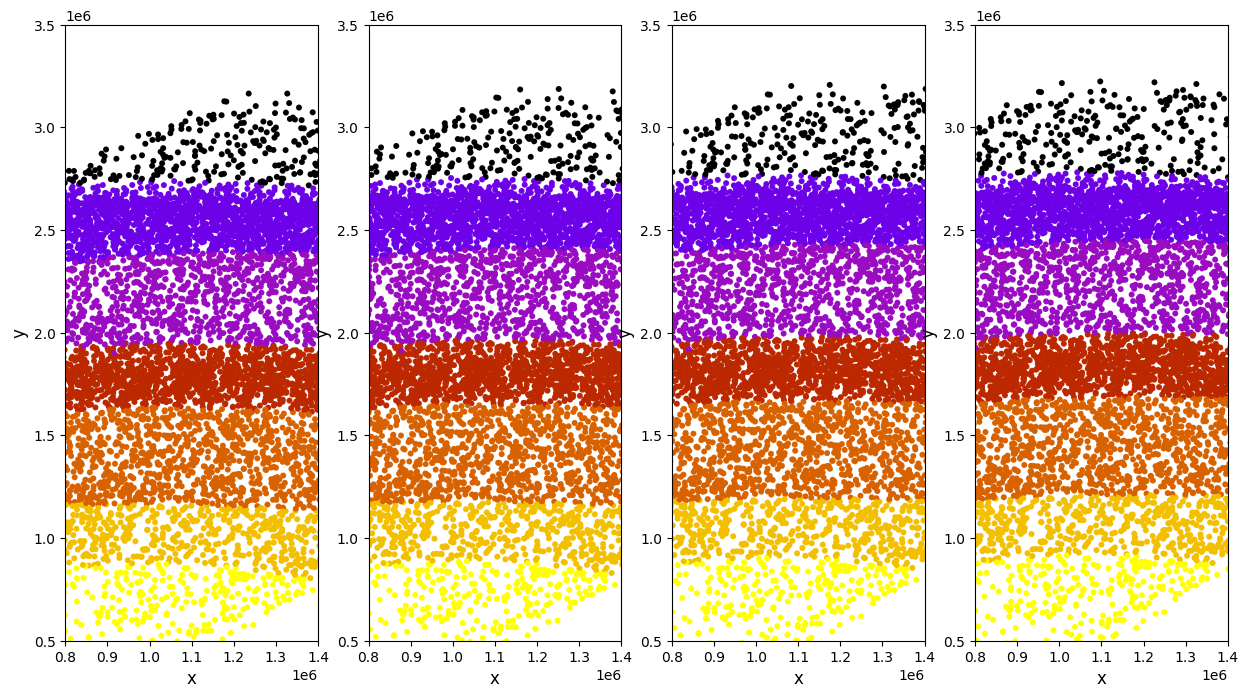

In [19]:
# plot the results
fig=plt.figure(figsize=(15,8))

for ii in range(4):

    nodeprex_new = []
    nodeprez_new = []       
    nodeprey_new = [] 
    nodepremtype_new = []    

    for gid in range(len(nodeprex)):
        
        x0, y0, z0 = nodeprex[gid], -nodeprey[gid]+2321399.37744675, nodeprez[gid]

        v, axis, theta = [x0, y0, z0], [0, 0, 1], 0.03*ii + 1.17 - 0.43
        M0 = M(axis, theta)
        vn = dot(M0,v)
            
        nodeprex_new.append(vn[0])
        nodeprey_new.append(vn[1])
        nodeprez_new.append(vn[2])
        nodepremtype_new.append(nodepremtype[gid])


    minx, miny, minz = min(nodeprex_new), min(nodeprey_new), min(nodeprez_new)
    minx, miny, minz


    plt.subplot(1,4,1+ii)
    plt.scatter(nodeprex_new - minx,nodeprey_new - miny, lw=0.05, s=18,
                c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
    plt.xlabel('x', fontsize=12)
    plt.ylabel('y', fontsize=12)
    plt.ylim(500000, 3500000)
    plt.xlim(800000, 1400000);


/tmp/ipykernel_2650142/80034222.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
/tmp/ipykernel_2650142/80034222.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
/tmp/ipykernel_2650142/80034222.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))


Text(0, 0.5, 'z')

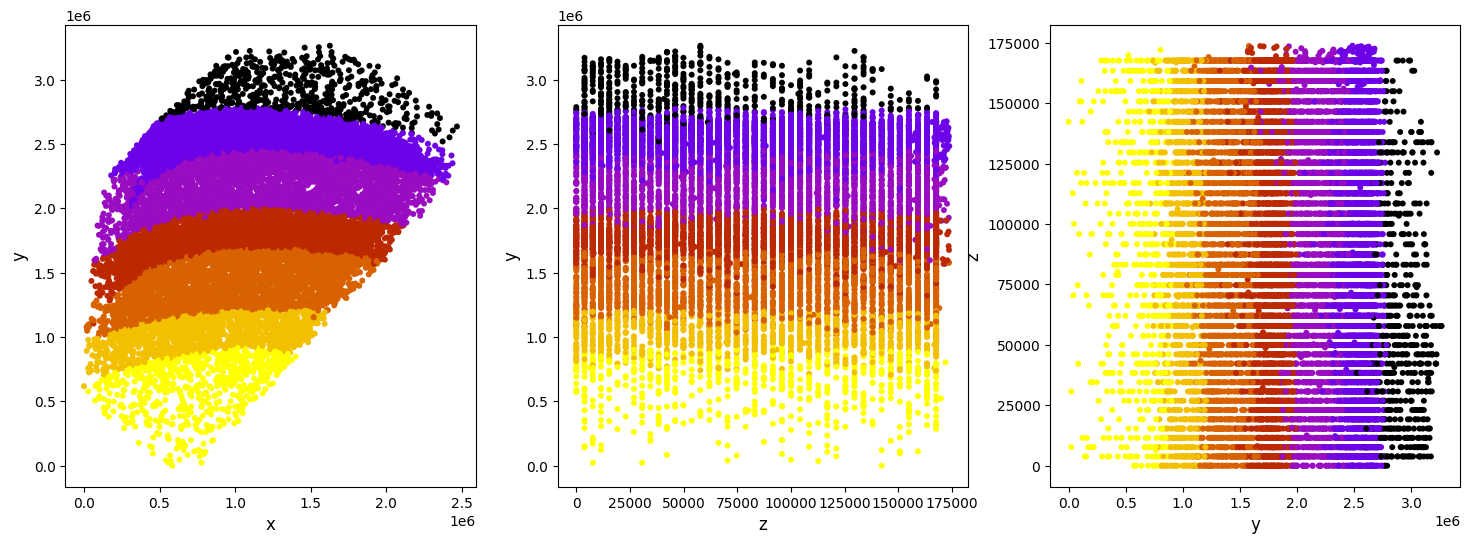

In [20]:
# plot the results
fig=plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.scatter(nodeprex_new-minx,nodeprey_new-miny, lw=0.05, s=18,
            c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)


plt.subplot(1,3,2)
plt.scatter(nodeprez_new-minz,nodeprey_new-miny, lw=0.05, s=18,
            c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('z', fontsize=12)
plt.ylabel('y', fontsize=12)


plt.subplot(1,3,3)
plt.scatter(nodeprey_new-miny,nodeprez_new-minz, lw=0.05, s=18,
            c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('y', fontsize=12)
plt.ylabel('z', fontsize=12)

/tmp/ipykernel_2650142/2705879612.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))


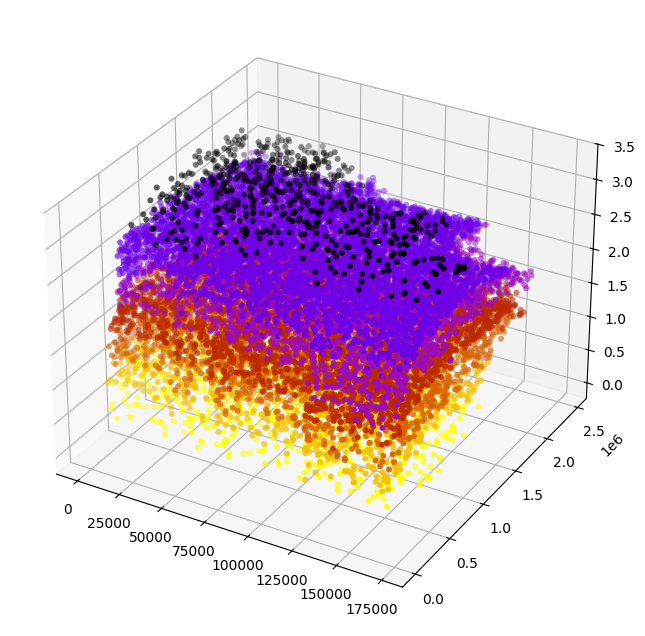

In [21]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')

ax.scatter(nodeprez_new-minz,nodeprex_new-minx,nodeprey_new-miny,lw=0.05, s=18,
            c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))

In [22]:
x_new, y_new, z_new = nodeprex_new-minx, nodeprey_new-miny,nodeprez_new-minz

/tmp/ipykernel_2650142/899536616.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
/tmp/ipykernel_2650142/899536616.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))


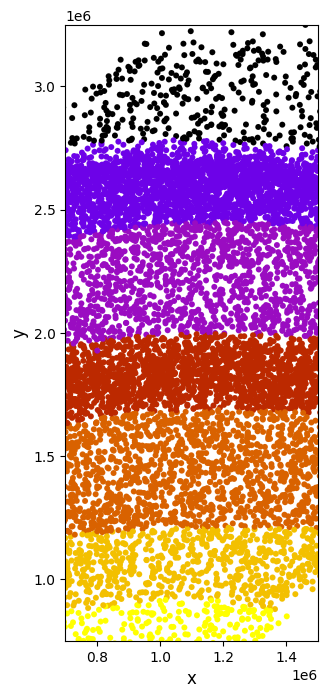

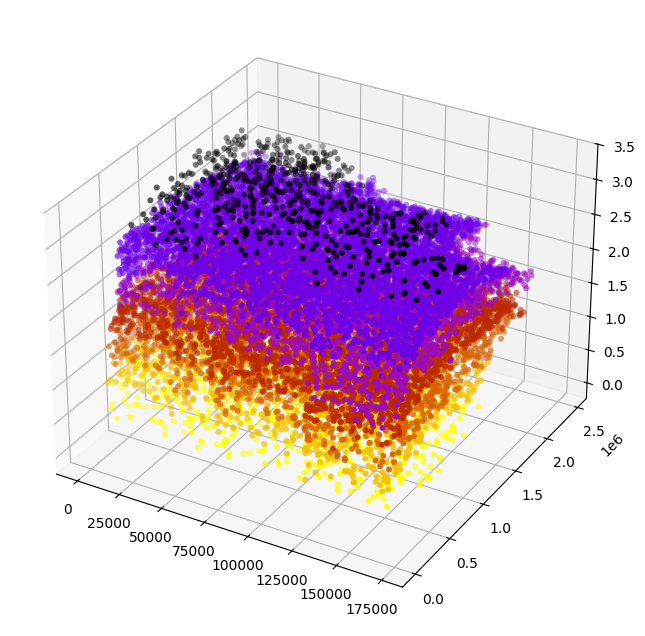

In [23]:
# plot the results
fig=plt.figure(figsize=(15,8))

plt.subplot(1,4,1+ii)
plt.scatter(x_new,y_new, lw=0.05, s=18,
                c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.ylim(750000, 3250000)
plt.xlim(700000, 1500000);


fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')

ax.scatter(z_new, x_new, y_new, lw=0.05, s=18,
            c=nodepremtype_new, cmap=plt.cm.get_cmap('gnuplot', 12))


In [24]:
ind_cell_df.keys()

Index(['id_new', 'agglo_seg', 'x', 'y', 'z', 'type', 'layer', 'linfo', 'info',
       'neuron', 'excitatory synapses', 'inhibitory synapses',
       'cortical layer', 'cell type', 'synapses', 'repetitions', 'labels',
       'glia', 'spiny', 'pyr', 'EI'],
      dtype='object')

In [25]:
ind_cell_df['EI'].value_counts()

exc    10575
inh     5394
Name: EI, dtype: int64

In [26]:
lll = []
lll2 = []
mtype = []
mtype2 = []
for id, nn in enumerate(list(ind_cell_df['EI'].values)):
    if 'inh' in nn or nodepremtype_new[id]==1:
        lll2.append(nn)
        mtype.append('inhibitory')
        if nodepremtype_new[id]==2 or nodepremtype_new[id]==3:
            mtype2.append('L23I')
        else:
            mtype2.append('L'+str(nodepremtype_new[id])+'I')
    else:
        lll.append(nn)
        mtype.append('excitatory')    
        if nodepremtype_new[id]==2 or nodepremtype_new[id]==3:
            mtype2.append('L23E')
        else:
            mtype2.append('L'+str(nodepremtype_new[id])+'E')
        

In [27]:
np.unique(mtype2, return_counts=True)

(array(['L1I', 'L23E', 'L23I', 'L4E', 'L4I', 'L5E', 'L5I', 'L6E', 'L6I',
        'L7E', 'L7I'], dtype='<U4'),
 array([ 571, 4864, 2858, 2681,  857, 1710,  665,  947,  188,  373,  255]))

In [28]:
np.unique(mtype, return_counts=True)

(array(['excitatory', 'inhibitory'], dtype='<U10'), array([10575,  5394]))

In [29]:
ind_cell_df.keys()

Index(['id_new', 'agglo_seg', 'x', 'y', 'z', 'type', 'layer', 'linfo', 'info',
       'neuron', 'excitatory synapses', 'inhibitory synapses',
       'cortical layer', 'cell type', 'synapses', 'repetitions', 'labels',
       'glia', 'spiny', 'pyr', 'EI'],
      dtype='object')

In [30]:
nodes_new = pd.DataFrame({'id': list(ind_cell_df['agglo_seg'].values), 'x': list(ind_cell_df['x'].values), 'y': list(ind_cell_df['y'].values), 'z': list(ind_cell_df['z'].values),
                          'x_new': list(x_new), 'y_new': list(y_new), 'z_new': list(z_new),
                          'layer': list(ind_cell_df['linfo'].values), 'EI': list(mtype), 'mtype': list(mtype2), 'type': list(ind_cell_df['type'].values),  
                          'Esyns': list(ind_cell_df['excitatory synapses'].values), 'Isyns': list(ind_cell_df['inhibitory synapses'].values),'syns': list(ind_cell_df['synapses'].values),
                          'info': list(ind_cell_df['info'].values)}, index=list(range(len(x_new))))  

# nodes_new.to_hdf('nodes_new.h5', key='nodes_new', mode='w')  

In [31]:
def distance3D(gidpre,gidpost):
    return np.sqrt(np.power(nodes_new['x'][gidpre]-nodes_new['x'][gidpost],2)+np.power(nodes_new['y'][gidpre]-nodes_new['y'][gidpost],2)+np.power(nodes_new['z'][gidpre]-nodes_new['z'][gidpost],2))

In [32]:
def distance3D_new(gidpre,gidpost):
    return np.sqrt(np.power(nodes_new['x_new'][gidpre]-nodes_new['x_new'][gidpost],2)+np.power(nodes_new['y_new'][gidpre]-nodes_new['y_new'][gidpost],2)+np.power(nodes_new['z_new'][gidpre]-nodes_new['z_new'][gidpost],2))

In [33]:
node_distance3D = []    
for gid in range(len(nodeprex)):
    node_distance3D.append(distance3D(100,gid) - distance3D_new(100,gid))

In [34]:
max(node_distance3D), min(node_distance3D)

(4.656612873077393e-10, -6.984919309616089e-10)

In [35]:
mean_z = np.mean(z_new)
mean_x = 1100000.0
mean_x, mean_z

(1100000.0, 84452.11716450623)

In [36]:
def distance2Dmean(gidpre, mean_x, mean_z):
    return np.sqrt(np.power(nodes_new['x_new'][gidpre]-mean_x,2)+np.power(nodes_new['z_new'][gidpre]-mean_z,2))

In [37]:
distance2Dcenter = [distance2Dmean(gidpre, mean_x, mean_z) for gidpre in range(len(x_new))]

In [38]:
distance2Dcenter2 = np.array(distance2Dcenter)/1000.0
x_new2 = np.array(x_new)/1000.0
z_new2 = np.array(z_new)/1000.0
y_new2 = np.array(y_new)/1000.0
nodepremtype_new2 = np.array(nodepremtype_new)

In [39]:
d2d = 400
len(distance2Dcenter2[np.where(distance2Dcenter2 < d2d)])

7528

In [40]:
len(ind_cell_df['agglo_seg'].values), len(np.unique(ind_cell_df['agglo_seg'].values)), len(ind_cell_df['agglo_seg'].values) - len(np.unique(ind_cell_df['agglo_seg'].values))

(15969, 15969, 0)

In [41]:
nodes_new = pd.DataFrame({'id': list(ind_cell_df['agglo_seg'].values), 'x': list(ind_cell_df['x'].values), 'y': list(ind_cell_df['y'].values), 'z': list(ind_cell_df['z'].values),
                          'x_new': list(x_new2), 'y_new': list(y_new2), 'z_new': list(z_new2), 'distance2Dcenter': list(distance2Dcenter2),
                          'layer': list(ind_cell_df['linfo'].values), 'EI': list(mtype), 'mtype': list(mtype2), 'type': list(ind_cell_df['type'].values),  
                          'Esyns': list(ind_cell_df['excitatory synapses'].values), 'Isyns': list(ind_cell_df['inhibitory synapses'].values),'syns': list(ind_cell_df['synapses'].values),                  
                          'info': list(ind_cell_df['info'].values)}, index=list(range(len(x_new))))  

# nodes_new.to_hdf('nodes_new.h5', key='nodes_new', mode='w')  
# nodes_new = nodes_new.drop_duplicates(subset=['id'], keep='first')
nodes_new

,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,105572531279,1336832,2275647,169884,1128.532093,522.551098,169.884,90.070456,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,6525902368,1523184,2008880,91605,1057.440803,840.100666,91.605,43.156100,7,excitatory,L7E,pyramidal neuron,2919,835,3754,WMpyramidalneuron
2,6526033781,1565984,1840864,121173,962.341208,985.074055,121.173,142.472335,6,excitatory,L6E,pyramidal neuron,2855,883,3738,L6pyramidalneuronbipolar
3,6527305613,2122232,1725400,108501,1252.534992,1473.470759,108.501,154.419146,5,excitatory,L5E,pyramidal neuron,615,359,974,L5pyramidalneuron
4,6527669458,1989968,1976000,100053,1348.198826,1206.745139,100.053,248.688650,6,excitatory,L6E,pyramidal neuron,2603,840,3443,L6pyramidalneuronbipolar
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15964,5344594921,961928,1605040,53760,380.656528,698.474084,53.760,719.997942,7,inhibitory,L7I,unknown cell,571,290,861,WMunknown-type
15965,22611620829,1501320,1407584,57813,598.970138,1229.766630,57.813,501.737547,5,inhibitory,L5I,unknown cell,261,149,410,L5unknown-type
15966,1697644856,2505288,746104,19200,788.396961,2417.042931,19.200,318.361889,2,inhibitory,L23I,unknown cell,172,122,294,L2unknown-typegrey
15967,34011994965,2039864,2090776,167637,1466.569238,1166.105422,167.637,375.889254,6,inhibitory,L6I,unknown cell,349,156,505,L6unknown-typegrey


In [42]:
nodes_new['mtype'].value_counts()

L23E    4864
L23I    2858
L4E     2681
L5E     1710
L6E      947
L4I      857
L5I      665
L1I      571
L7E      373
L7I      255
L6I      188
Name: mtype, dtype: int64

In [43]:
nodes_new[nodes_new['distance2Dcenter'] < 300.0]['mtype'].value_counts()

L23E    1622
L4E      927
L23I     927
L5E      689
L6E      387
L4I      268
L1I      252
L5I      239
L7E      199
L7I       91
L6I       71
Name: mtype, dtype: int64

In [44]:
nodes_new[(nodes_new['distance2Dcenter'] < 50.0) & (nodes_new['syns'] < 1000.0) & (nodes_new['mtype'] == "L23E")]["id"].values

array([28484348911,  2295540138, 28644171552])

In [45]:
nodes_new[nodes_new['id'] == 2964441917]

,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
5125,2964441917,2720200,985856,74709,1110.356383,2413.830424,74.709,14.219107,3,excitatory,L23E,pyramidal neuron,7286,1897,9183,L3pyramidalneuron


In [46]:
L23_sub = nodes_new[(nodes_new['distance2Dcenter'] < 300.0) & (nodes_new['distance2Dcenter'] > 0.0) & (nodes_new['mtype'] == "L23E") & (nodes_new['z_new'] >= 11.52) & (nodes_new['z_new'] <= 121.173) & (nodes_new['syns'] >= 4000.0)]
L23_sub = L23_sub.sort_values(by='distance2Dcenter', ascending=True) #   & (nodes_new['EI'] == "excitatory") & (nodes_new['layer'] >= 5)
L23_sub = L23_sub.sort_values(by='y_new', ascending=True)
L23_sub

,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
5561,2947986035,2255656,1102616,66261,883.007765,1992.230340,66.261,217.753409,3,excitatory,L23E,pyramidal neuron,5736,1425,7161,L3pyramidalneuron
5564,2962791579,2209760,1050640,57813,813.678946,1993.439584,57.813,287.557627,3,excitatory,L23E,pyramidal neuron,4435,1489,5924,L3pyramidalneurongrey
6070,3355455838,2296712,1131848,112725,932.286674,2002.798882,112.725,170.079734,3,excitatory,L23E,pyramidal neuron,4941,1469,6410,L3pyramidalneuron
5542,2962105270,2233376,1061832,95829,837.875740,2003.313362,95.829,262.371038,3,excitatory,L23E,pyramidal neuron,3840,1185,5025,L3pyramidalneuron
5164,3006244044,2212496,1038008,46080,806.203857,2003.983595,46.080,296.291399,3,excitatory,L23E,pyramidal neuron,3199,1067,4266,L3pyramidalneurongrey
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9712,2951431928,3043560,910632,70485,1273.074059,2703.214766,70.485,173.636719,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,3220,1165,4385,L2neuronexcitatory/spiny-with-atypical-treethi...
9980,635743109,2798160,638728,46080,906.813056,2705.627827,46.080,196.960947,2,excitatory,L23E,spiny stellate neuron,3200,1121,4321,L2neuronspiny-stellatethin-apical-dendrite
9126,2034430344,3067872,930264,38400,1303.968707,2707.906193,38.400,209.102920,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,4171,1587,5758,L2neuronexcitatory/spiny-with-atypical-tree
6783,1102726098,2987976,835096,15360,1179.821381,2713.175005,15.360,105.570704,2,excitatory,L23E,pyramidal neuron,2898,1324,4222,L2pyramidalneuron


In [47]:
ind_cell_df[(ind_cell_df["agglo_seg"] == 2775797778) | (ind_cell_df["agglo_seg"] == 2833193133)]

,id_new,agglo_seg,x,y,z,type,layer,linfo,info,neuron,...,inhibitory synapses,cortical layer,cell type,synapses,repetitions,labels,glia,spiny,pyr,EI
5396,19076,2775797778,2746272,960976,95829,pyramidal neuron,2,2,L2pyramidalneuron,True,...,1191,Layer 3,pyramidal neuron,5884,1,pyramidal neuron_L2pyramidalneuron_pyramidal n...,False,False,True,exc
5600,19069,2833193133,2746648,972232,74709,pyramidal neuron,2,3,L3pyramidalneuron,True,...,918,Layer 3,pyramidal neuron,4022,1,pyramidal neuron_L3pyramidalneuron_pyramidal n...,False,False,True,exc


In [48]:
L23_sub["EI"].value_counts()

excitatory    465
Name: EI, dtype: int64

In [50]:
# nodes_new.to_csv('cell_positions_h01_rotated_full.csv')

In [51]:
nodes_new[nodes_new["id"] == 3954359648]

,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
8307,3954359648,2711528,1291408,70485,1329.980266,2201.221445,70.485,230.404,3,excitatory,L23E,pyramidal neuron,6775,1934,8709,L3glialoligodendrocyte


/tmp/ipykernel_2650142/772039764.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=distance2Dcenter2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))
/tmp/ipykernel_2650142/772039764.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))
/tmp/ipykernel_2650142/772039764.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new2[np.

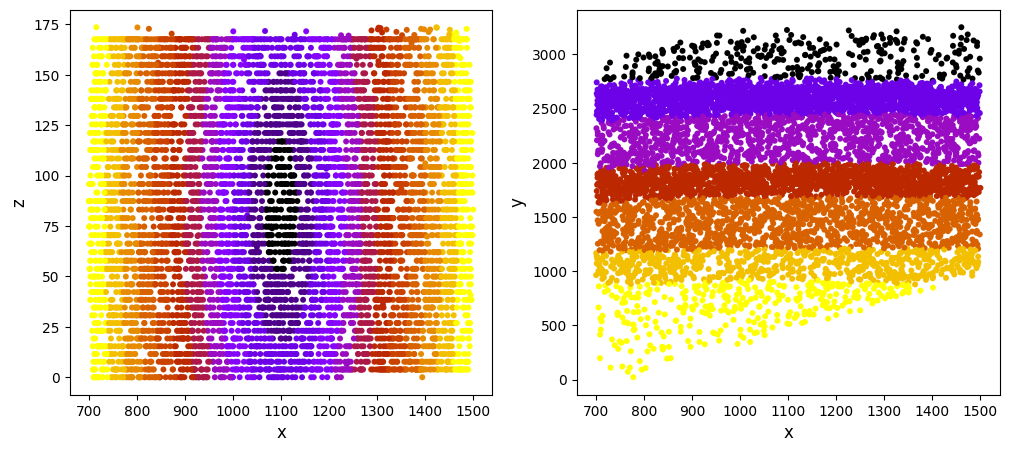

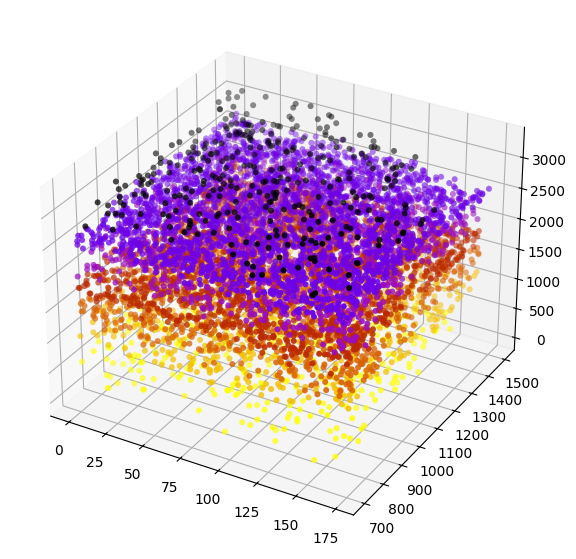

In [52]:
d2d = 400

# plot the results
fig=plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(x_new2[np.where(distance2Dcenter2 < d2d)],z_new2[np.where(distance2Dcenter2 < d2d)], lw=0.05, s=18,
                c=distance2Dcenter2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('x', fontsize=12)
plt.ylabel('z', fontsize=12)
# plt.ylim(0, 2500000)
# plt.xlim(1000000, 1420000);

plt.subplot(1,2,2)
plt.scatter(x_new2[np.where(distance2Dcenter2 < d2d)],y_new2[np.where(distance2Dcenter2 < d2d)], lw=0.05, s=18,
                c=nodepremtype_new2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
# plt.ylim(0, 2500000)
# plt.xlim(1000000, 1420000);

fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(projection='3d')

ax.scatter(z_new2[np.where(distance2Dcenter2 < d2d)], x_new2[np.where(distance2Dcenter2 < d2d)],y_new2[np.where(distance2Dcenter2 < d2d)], lw=0.05, s=18,
            c=nodepremtype_new2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))


/tmp/ipykernel_2650142/2723339609.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  c=nodepremtype_new2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))


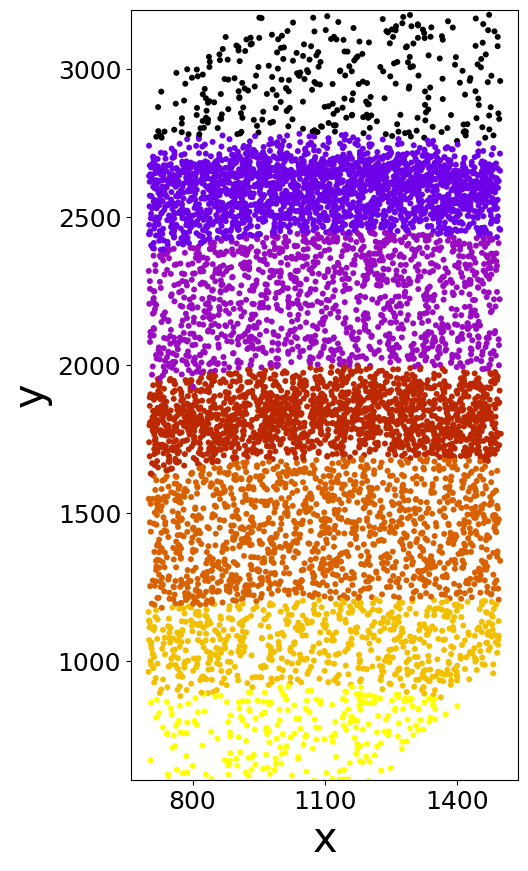

In [53]:
# plot the results
fig=plt.figure(figsize=(5,10))

plt.scatter(x_new2[np.where(distance2Dcenter2 < d2d)],y_new2[np.where(distance2Dcenter2 < d2d)], lw=0.05, s=18,
                c=nodepremtype_new2[np.where(distance2Dcenter2 < d2d)], cmap=plt.cm.get_cmap('gnuplot', 12))
plt.xlabel('x', fontsize=30)
plt.ylabel('y', fontsize=30)
# plt.xlim(800, 1400)
plt.ylim(600, 3200);
plt.xticks([800, 1100, 1400],fontsize=18)
plt.yticks(fontsize=18);


In [54]:
d2d = 400
len(nodes_new[nodes_new['distance2Dcenter'] < d2d]), len(nodes_new), len(nodes_new[nodes_new['distance2Dcenter'] < d2d])/len(nodes_new)

(7528, 15969, 0.4714133633915712)